<a href="https://pulse.simudyne.com"><img src="_notebook_assets/Simudyne_Symbol_Logotype_BLUE_RGB.png" width="320" alt="Simudyne"></a>

# Pulse FM Previously run results

> **Simudyne Pulse · Production** — runs with the Simudyne-[Pulse](https://pulse.simudyne.com) SDK. 

A run is not lost when the variable holding it is. Everything lives on Pulse, keyed by `job_id` and `sim_id`, so a fresh kernel can pick up any run on your account.

📖 **Docs:** [Simulations](https://pulse.simudyne.com/docs/simulations) · [Download data](https://pulse.simudyne.com/docs/available-data) · [API reference](https://pulse.simudyne.com/docs/api-reference)

### Setup

`pip install simudyne-pulse` and set your key — `export SIMUDYNE_API_KEY=pk_live_...`, or pass
`PulseABM(api_key=...)`. Keys come from your [account page](https://pulse.simudyne.com/docs/api-keys); see
[Authentication](https://pulse.simudyne.com/docs/authentication).

A production run is a **job**: `run()` returns at once with a `job_id`, the model runs on
Pulse's compute, and `wait()` below polls it every 20 seconds until it finishes.

In [1]:
import time

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from IPython.display import clear_output
from simudyne import PulseABM

client = PulseABM()   # reads SIMUDYNE_API_KEY; points at production by default


def wait(job_id, every=20):
    """Poll a job until every run has finished and its results can be read."""
    start = time.time()
    while True:
        status = client.simulation.get_job_status(job_id)
        clear_output(wait=True)
        note = "" if status["is_complete"] else status.get("message") or ""
        print(f"{job_id}  {time.time() - start:4.0f}s  {status['status_summary']}  {note}")
        if status["is_complete"]:
            sims = client.simulation.get_job_results(job_id)["simulations"]
            if all(s.get("metrics") or s["status"] in ("error", "failed") for s in sims):
                break
        time.sleep(every)
    if status["has_errors"]:
        print(client.simulation.get_job_logs(job_id)[-2000:])
    return status


def generated(sim_id):
    """The model's own rows: sim_data.parquet minus the real warm-start context."""
    book = client.simulation.get_sim_data(sim_id)
    segments = client.simulation.get_sim_metrics(sim_id)["segments"]
    return pl.concat([book.slice(a, b - a) for a, b in (s["generated"] for s in segments)])


def mid(frame):
    return frame.select("timestamp", mid=(pl.col("bid_price_1") + pl.col("ask_price_1")) / 2)


def style(ax, title, ylabel="mid"):
    ax.set(title=title, ylabel=ylabel)
    ax.grid(alpha=0.25)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.margins(x=0)

## 1. Keep the `job_id`

`run()` hands you a `job_id` and its `sim_ids`. That id is the whole of what you need to come
back — nothing is cached in the `job` dict itself.

In [2]:
print("Models available to you:", [m["production_name"] for m in client.fm.models()["models"]])
MODEL = "flow-lse-1-54M"   # the public LSE model

job = client.simulation.run(engine="fm", model_id=MODEL, duration_minutes=5, seed=7)
kept = job["job_id"]
del job

wait(kept)
client.simulation.get_job_results(kept)["simulations"][0]["metrics"]["generated_window"]

44eea3fd-848e-40cf-b459-f55365286e33    63s  {'complete': 1}  


{'start': '2026-06-01T08:00:56', 'end': '2026-06-01T08:05:55'}

## 2. A new kernel — list your jobs

`get_jobs()` is your account's history, newest first. A job appears as soon as it is submitted,
so it includes runs still going and runs that failed.
See [How a job progresses](https://pulse.simudyne.com/docs/simulations).

In [3]:
jobs = client.simulation.get_jobs(limit=10)
print(jobs["total"], "jobs on this account")

pl.DataFrame([
    {"created_at": j["created_at"], "job_id": j["job_id"], "sims": len(j["sim_ids"]),
     "first_sim": j["sim_ids"][0] if j["sim_ids"] else None}
    for j in jobs["jobs"]
])

315 jobs on this account


created_at,job_id,sims,first_sim
str,str,i64,str
"""2026-11-27 15:12:25.042053""","""44eea3fd-848e-40cf-b459-f55365…",1,"""bmll:lse:SHEL:2026-06-01:FM-fl…"
"""2026-11-27 15:07:25.435922""","""bbcc65d4-d2ab-44a1-8b1a-13930e…",4,"""bmll:lse:TSCO:2025-09-01:FM-fl…"
"""2026-11-27 14:59:56.714146""","""8c2401c2-0a95-49a7-90ab-35bbc0…",6,"""bmll:lse:TSCO:2025-09-01:FM-fl…"
"""2026-11-27 14:57:25.581747""","""b216a283-16c0-4df2-9896-94a124…",2,"""bmll:lse:TSCO:2025-09-01:FM-fl…"
"""2026-11-27 14:52:04.206182""","""4ead2764-7586-46f1-a8a4-c89fb0…",3,"""bmll:lse:TSCO:2025-09-01:FM-fl…"
"""2026-11-27 14:50:47.450320""","""a5563dd1-7e98-4457-8d31-515dcf…",3,"""bmll:lse:SHEL:2026-06-01:FM-fl…"
"""2026-11-27 14:48:29.253986""","""c5036adc-6456-414e-980d-83a079…",3,"""bmll:lse:SHEL:2026-06-01:FM-fl…"
"""2026-11-27 14:45:28.048792""","""a71e2544-4f7c-45c3-8e0b-6006f6…",3,"""na:na:testdata:na:FM-flob-adal…"
"""2026-11-27 14:41:53.951898""","""6b7cd7f9-bed8-410a-8e11-b3cf67…",3,"""na:na:testdata:na:FM-flob-adal…"


The columns of a `sim_id` are the whole record of what ran
([Understanding simulation IDs](https://pulse.simudyne.com/docs/simulations)):

| field | what it is |
|---|---|
| `provider`, `exchange`, `symbol`, `date` | the day the model was given |
| `model` | the engine and its version |
| `window` | the run's own generated window, `HHMM-HHMM` |
| `params` | a hash of the seed, horizon, device and resolved `model_args` |
| `algo` | `baseline`, or the algo an `exec_algos=` run carried |
| `draw` | which Monte Carlo draw |

Two runs differing only by a knob get a different `params`, so nothing is ever overwritten.

In [4]:
FIELDS = ("provider", "exchange", "symbol", "date", "model", "cal", "window", "params", "scenario", "algo", "draw")

sims = pl.DataFrame([
    dict(zip(FIELDS, sim_id.split(":")), job_id=j["job_id"], sim_id=sim_id)
    for j in jobs["jobs"] for sim_id in j["sim_ids"]
])
sims.select("job_id", "symbol", "date", "window", "params", "algo", "draw")

job_id,symbol,date,window,params,algo,draw
str,str,str,str,str,str,str
"""44eea3fd-848e-40cf-b459-f55365…","""SHEL""","""2026-06-01""","""na""","""faf34893""","""baseline""","""0000"""
"""bbcc65d4-d2ab-44a1-8b1a-13930e…","""TSCO""","""2025-09-01""","""0800-0810""","""78603398""","""css_026b1e7f""","""0001"""
"""bbcc65d4-d2ab-44a1-8b1a-13930e…","""TSCO""","""2025-09-01""","""0800-0810""","""78603398""","""css_026b1e7f""","""0000"""
"""bbcc65d4-d2ab-44a1-8b1a-13930e…","""TSCO""","""2025-09-01""","""0800-0810""","""78603398""","""baseline""","""0001"""
"""bbcc65d4-d2ab-44a1-8b1a-13930e…","""TSCO""","""2025-09-01""","""0800-0810""","""78603398""","""baseline""","""0000"""
…,…,…,…,…,…,…
"""a71e2544-4f7c-45c3-8e0b-6006f6…","""testdata""","""na""","""na""","""f91dcf15""","""baseline""","""0000"""
"""6b7cd7f9-bed8-410a-8e11-b3cf67…","""testdata""","""na""","""na""","""bb0752e0""","""baseline""","""0002"""
"""6b7cd7f9-bed8-410a-8e11-b3cf67…","""testdata""","""na""","""na""","""bb0752e0""","""baseline""","""0001"""


## 3. Rebuild a run from its id

Status, results, files and logs all take the id — no other state needed.

In [5]:
job_id = jobs["jobs"][0]["job_id"]
status = client.simulation.get_job_status(job_id)
print(status["status_summary"], "| errors:", status["has_errors"])

done = [s["sim_id"] for s in status["simulations"] if s["status"] in ("complete", "completed")]
done

{'complete': 1} | errors: False


['bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:na:faf34893:normal_99914b93:baseline:0000']

['l2_by_second.parquet', 'mid_price_by_min.parquet', 'params.json', 'results.json', 'sim_data.parquet']


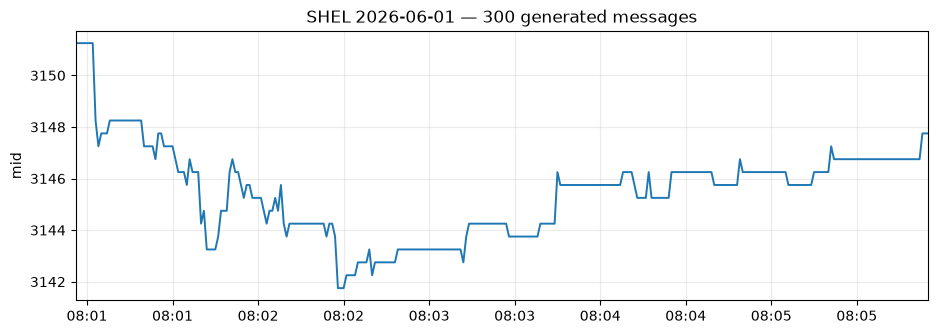

In [6]:
sim_id = done[0]
print(client.simulation.list_sim_files(sim_id)["files"])

m = mid(generated(sim_id))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(m["timestamp"], m["mid"], lw=1.4)
style(ax, f"{sim_id.split(':')[2]} {sim_id.split(':')[3]} — {len(m):,} generated messages")

And when a run **failed**, the log is still there — the reason is at the end:

In [7]:
print(client.simulation.get_job_logs(job_id)[-600:])

del_id": "flob-adaln-rf-1s-lse-54m",\n  "version": "1.0.2",\n  "gen_method": "FM-flob-adaln-rf-1s-lse-54m_v1.0.2",\n  "job_id": "44eea3fd-848e-40cf-b459-f55365286e33",\n  "seed": 7,\n  "n_runs": 1,\n  "exec_algo": false,\n  "horizon": null,\n  "device": "cpu",\n  "batches": 1,\n  "sims": {\n    "bmll:lse:SHEL:2026-06-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:s7:Session1:r0:44eea3fd": [\n      "/tmp/fm_out/data/SHEL_2026-06-01_Session1_0.parquet"\n    ]\n  },\n  "output_files": [\n    "/tmp/fm_out/data/SHEL_2026-06-01_Session1_0.parquet"\n  ],\n  "elapsed_secs": 44.57,\n  "status": "complete"\n}\n'


## 4. Pairing an execution arm with its baseline

Same day, same window, same `params` — only `algo` and `draw` differ, so the impact of the
orders is a join on everything else.

In [8]:
arms = sims.filter(pl.col("algo") != "baseline")
if arms.height:
    one = arms.row(0, named=True)
    mate = sims.filter((pl.col("window") == one["window"]) & (pl.col("params") == one["params"])
                       & (pl.col("algo") == "baseline") & (pl.col("draw") == one["draw"]))
    print(one["algo"], one["draw"], "→", mate["sim_id"][0] if mate.height else "no matching baseline")
else:
    print("no execution runs in the last 10 jobs — see 02-exec-algos.ipynb")

css_026b1e7f 0001 → bmll:lse:TSCO:2025-09-01:FM-flob-adaln-rf-1s-lse-54m_v1.0.2:na:0800-0810:78603398:normal_99914b93:baseline:0001


## 5. The shared library — runs you did not make

`list_cached()` is a library of pre-computed baseline simulations readable by every account,
including the free tier. Reading one you have not downloaded before uses your daily download
allowance — see [Download limits](https://pulse.simudyne.com/docs/simulations#download-limits).

In [9]:
cached = client.simulation.list_cached()
pl.DataFrame(cached["simulations"]).select("symbol", "date", "scenario", "n_runs", "example_sim_id").head(10)

symbol,date,scenario,n_runs,example_sim_id
str,str,str,i64,str
"""1""","""2025-12-01""","""flash_crash""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-01""","""normal""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-02""","""flash_crash""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-02""","""normal""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-03""","""flash_crash""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-03""","""normal""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-04""","""flash_crash""",5,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-04""","""normal""",10,"""bmll:hkex_securities:1:2025-12…"
"""1""","""2025-12-05""","""flash_crash""",5,"""bmll:hkex_securities:1:2025-12…"


---

- **Same session** — keep `job["job_id"]`.
- **Failed run** — `get_job_logs(job_id)`; the reason is the last lines.
- **New kernel** — `get_jobs()`, then any call that takes the id.
- **Someone else's baseline** — `list_cached()`.

`client.simulation.get_sim_data(sim_id).write_parquet("mine.parquet")` is still the cheapest
insurance. Bulk downloads: [Download data](https://pulse.simudyne.com/docs/available-data).